# CS4451 & CS9548: Foundations of Machine Learning — Assignment 1

**Due:** 23:59, October 22, 2026  
**Name:** Issar Manknojiya  **Student #:** 251366740

### Contents
| Part | Topic | Points |
|---|---|---|
| [1](#1-refreshing-mathematics) | Refreshing Mathematics | 25 |
| [2](#2-linear-and-polynomial-regression) | Linear and Polynomial Regression | 50 |
| [3](#3-regularization-and-cross-validation) | Regularization and Cross-Validation | 25 |

## 0. Setup
Imports, data loading, and helpers shared by Parts 2 and 3.

In [71]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.figsize": (6, 4), "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

In [72]:
xtr = np.loadtxt("hw1xtr.dat")   # training features
ytr = np.loadtxt("hw1ytr.dat")   # training targets
xte = np.loadtxt("hw1xte.dat")   # test features
yte = np.loadtxt("hw1yte.dat")   # test targets

print("train:", xtr.shape, ytr.shape)
print("test:", xte.shape, yte.shape)

train: (40,) (40,)
test: (20,) (20,)


In [73]:
def design_matrix(x, order):
    '''Return the m x (order+1) matrix [1, x, x^2, ..., x^order].'''
    return np.vander(x, order + 1, increasing=True)


def fit_linear_regression(X, y):
    '''Least-squares weights using the closed-form solution from Lecture 3.'''
    return np.linalg.solve(X.T @ X, X.T @ y)   # (X^T X)^-1 X^T y


def fit_ridge(X, y, lam):
    '''l2-regularized weights (Lecture 4, p.12). The bias term w0 is NOT penalized.'''
    D = np.eye(X.shape[1])
    D[0, 0] = 0                                  # do not penalize the bias w0
    return np.linalg.solve(X.T @ X + lam * D, X.T @ y)


def avg_error(X, y, w):
    '''Average error, Eq. (1):  (1/m) * sum_i (w^T x_i - y_i)^2'''
    return np.mean((X @ w - y) ** 2)


def plot_fit(x, y, w, order, title="", label="data"):
    '''Scatter the data and overlay the fitted polynomial curve.'''
    grid = np.linspace(0, 4, 200)
    plt.figure()
    plt.scatter(x, y, label=label)
    plt.plot(grid, design_matrix(grid, order) @ w, "r", label=f"order {order} fit")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.legend()
    plt.show()

---
## 1. Refreshing Mathematics

### 1(d) &nbsp; [5 points]
If $A=\begin{pmatrix}1&-2\\-2&6\end{pmatrix}$ and $B=\begin{pmatrix}2&-3\\-3&2\end{pmatrix}$, is $f(\mathbf{w})$ a convex function?
*(Hint: use Python/Matlab/R.)*

In [74]:
import numpy as np

A = np.array([[1, -2], [-2, 6]])
B = np.array([[2, -3], [-3, 2]])

H = A @ B + B.T @ A.T                  # Hessian from 1(c)
eigvals = np.linalg.eigvalsh(H)        # eigvalsh is for symmetric matrices (ascending order)
is_convex = bool(np.all(eigvals >= 0)) # convex  <=>  H is positive semi-definite

print(f"Eigenvalue 1 (smallest): {eigvals[0]:.4f}")
print(f"Eigenvalue 2 (largest):  {eigvals[1]:.4f}")
print(f"Determinant of H:        {np.linalg.det(H):.4f}")
print("-" * 40)
print(f"H positive semi-definite (all eigenvalues >= 0)? {is_convex}")
print(f"Answer: f(w) is {'CONVEX' if is_convex else 'NOT convex'}")

Eigenvalue 1 (smallest): -4.6757
Eigenvalue 2 (largest):  56.6757
Determinant of H:        -265.0000
----------------------------------------
H positive semi-definite (all eigenvalues >= 0)? False
Answer: f(w) is NOT convex


### 1(e) &nbsp; [5 points]
With the sigmoid $\sigma(a)=\dfrac{1}{1+e^{-a}}$ from Lecture 5, let $f(\mathbf{w}) = \log\sigma(\mathbf{w}^\top\mathbf{x})$ (natural log).
Compute $\nabla f(\mathbf{w})$ using the definition of gradient.

**Answer:**

_TODO_

---
## 2. Linear and Polynomial Regression
**[50 points]**

Implement linear and polynomial regression in any language of your choice. Training set: `hw1xtr.dat` (features), `hw1ytr.dat` (outputs). Test set: `hw1xte.dat`, `hw1yte.dat`.

Average error used throughout (Eq. 1):
$$\text{err} = \frac{1}{m}\sum_{i=1}^{m}\left(\mathbf{w}^\top\mathbf{x}_i - y_i\right)^2$$

### 2(a) &nbsp; [5 points]
Load the training data and plot it on one graph. Load the test data and plot it on another graph.

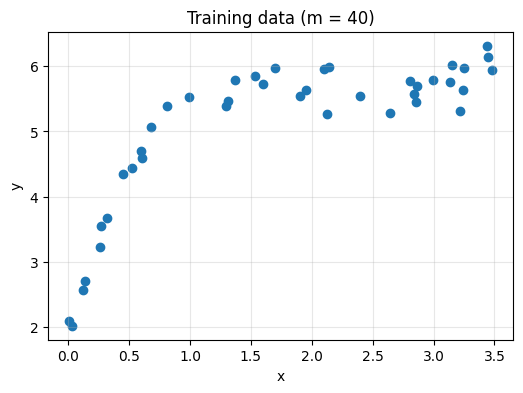

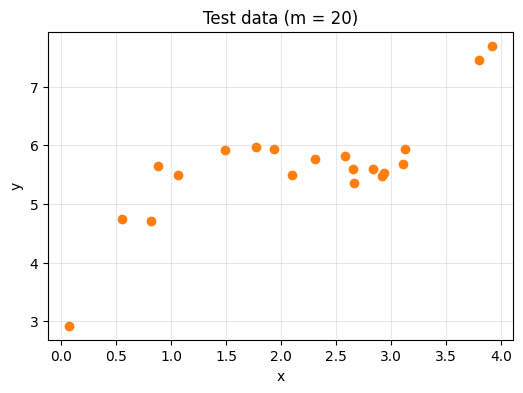

In [75]:
# Training data: its own figure
plt.figure()
plt.scatter(xtr, ytr, color="tab:blue")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Training data (m = 40)")
plt.show()

# Test data: a separate figure
plt.figure()
plt.scatter(xte, yte, color="tab:orange")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Test data (m = 20)")
plt.show()


### 2(b) &nbsp; [10 points]
Add a column of 1's to the features and use the linear regression formula from Lecture 3 to obtain a 2-dimensional weight vector.
Plot the regression line **and** the training data on the same graph. Report the average training error using Eq. (1).

weights [w0, w1]: [3.7138 0.7666]
average training error: 0.5085888601660319


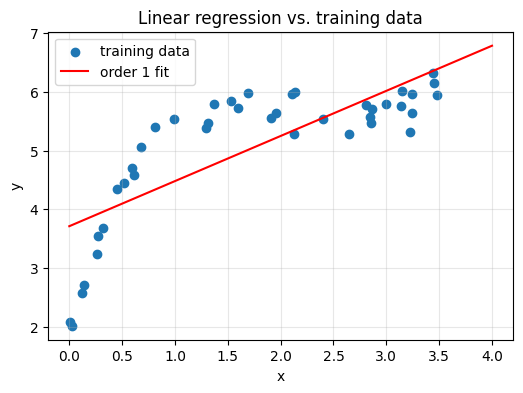

In [76]:
order = 1

Xtr = design_matrix(xtr, order)        # column of 1s + x
w1 = fit_linear_regression(Xtr, ytr)   # 2-dimensional weight vector [w0, w1]
train_err1 = avg_error(Xtr, ytr, w1)

print("weights [w0, w1]:", w1)
print("average training error:", train_err1)

plot_fit(xtr, ytr, w1, order, title="Linear regression vs. training data", label="training data")

### 2(c) &nbsp; [5 points]
Plot the regression line **and** the test data on the same graph. Report the average test error using Eq. (1).

average test error: 0.44391185790774934


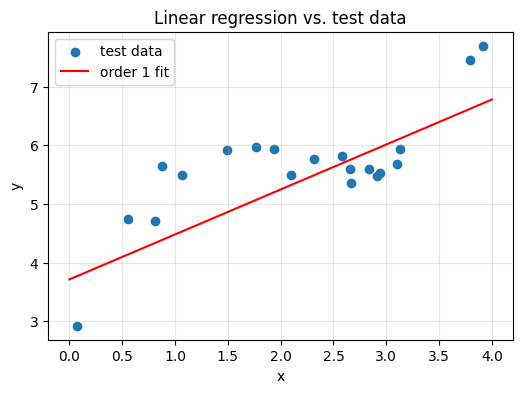

In [77]:
Xte = design_matrix(xte, 1)
test_err1 = avg_error(Xte, yte, w1)    # weights come from the TRAINING fit in 2(b)

print("average test error:", test_err1)

plot_fit(xte, yte, w1, 1, title="Linear regression vs. test data", label="test data")

**Answer (2b, 2c):**

Fitted line: $\hat y = 3.7138 + 0.7666\,x$

| Model | Train error | Test error |
|---|---|---|
| Linear (order 1) | 0.5086 | 0.4439 |

The data is visibly curved, so a straight line underfits: both errors are large and the line misses the shape of the data.

### 2(d) &nbsp; [10 points]
Implement **2nd-order** polynomial regression by adding the feature $x^2$. Repeat (b) and (c).
Compare training and test error. Is it a better fit than linear regression?

weights: [ 2.7794  2.6913 -0.5514]
order 2: train error = 0.2010,  test error = 0.8533


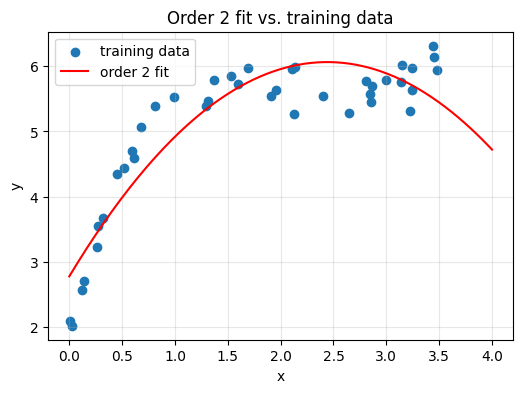

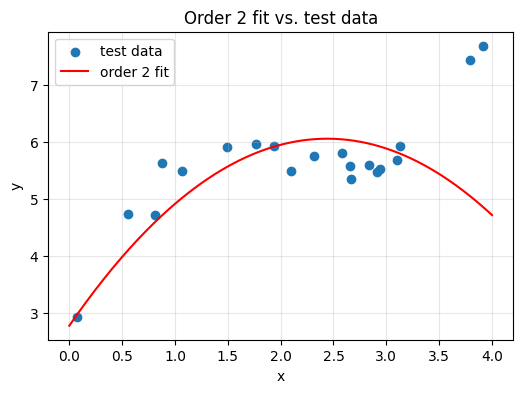

In [78]:
order = 2

Xtr, Xte = design_matrix(xtr, order), design_matrix(xte, order)
w2 = fit_linear_regression(Xtr, ytr)           # fit on TRAINING data only
train_err2 = avg_error(Xtr, ytr, w2)
test_err2 = avg_error(Xte, yte, w2)

print("weights:", w2)
print(f"order 2: train error = {train_err2:.4f},  test error = {test_err2:.4f}")

plot_fit(xtr, ytr, w2, order, title="Order 2 fit vs. training data", label="training data")
plot_fit(xte, yte, w2, order, title="Order 2 fit vs. test data", label="test data")

**Answer:**

| Model | Train error | Test error |
|---|---|---|
| Linear (order 1) | 0.5086 | 0.4439 |
| Quadratic (order 2) | 0.2010 | 0.8533 |

The training error drops from 0.5086 to 0.2010, so the quadratic follows the training data better. The test error, however, **rises** from 0.4439 to 0.8533. So it is **not** a better fit overall: it fits the training set better but generalizes worse. The test inputs reach $x\approx3.9$, past the largest training input ($\approx3.5$), and the parabola bends downward there, so it extrapolates badly.

### 2(e) &nbsp; [10 points]
Implement **3rd-order** polynomial regression by adding features $x^2, x^3$. Repeat (b) and (c).
Compare training and test error. Is it a better fit than linear and 2nd-order regression?

weights: [ 2.0134  5.9833 -2.9988  0.4672]
order 3: train error = 0.0392,  test error = 0.0564


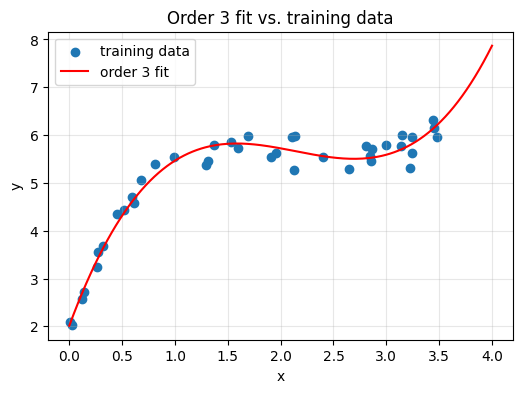

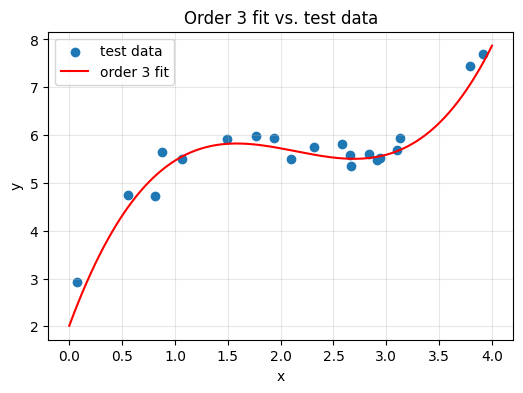

In [79]:
order = 3

Xtr, Xte = design_matrix(xtr, order), design_matrix(xte, order)
w3 = fit_linear_regression(Xtr, ytr)           # fit on TRAINING data only
train_err3 = avg_error(Xtr, ytr, w3)
test_err3 = avg_error(Xte, yte, w3)

print("weights:", w3)
print(f"order 3: train error = {train_err3:.4f},  test error = {test_err3:.4f}")

plot_fit(xtr, ytr, w3, order, title="Order 3 fit vs. training data", label="training data")
plot_fit(xte, yte, w3, order, title="Order 3 fit vs. test data", label="test data")

**Answer:**

| Model | Train error | Test error |
|---|---|---|
| Linear (order 1) | 0.5086 | 0.4439 |
| Quadratic (order 2) | 0.2010 | 0.8533 |
| Cubic (order 3) | 0.0392 | 0.0564 |

Yes. The cubic is better than both on **both** sets: training error 0.0392 (vs 0.5086 and 0.2010) and test error 0.0564 (vs 0.4439 and 0.8533). The data has a rise-then-flatten shape that a cubic can represent, and the cubic's test error is close to its training error, so it generalizes well.

### 2(f) &nbsp; [10 points]
Implement **4th-order** polynomial regression by adding features $x^2, x^3, x^4$. Repeat (b) and (c).
Compare with the previous results. Which order is best for fitting the data?

weights: [ 1.8964  6.7994 -4.1019  0.964  -0.071 ]
order 4: train error = 0.0356,  test error = 0.1272


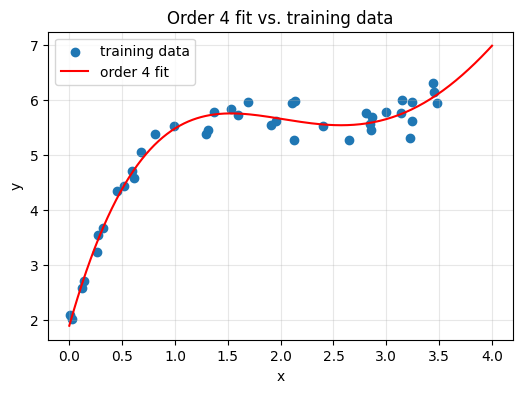

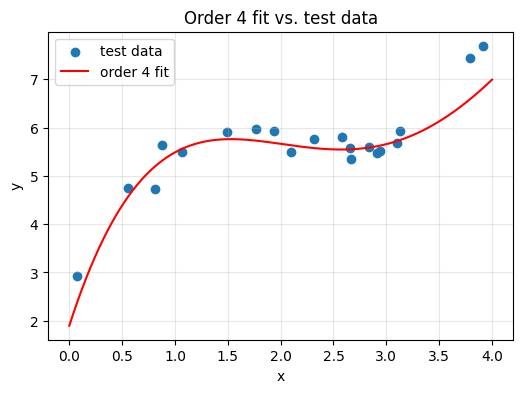

In [80]:
order = 4

Xtr, Xte = design_matrix(xtr, order), design_matrix(xte, order)
w4 = fit_linear_regression(Xtr, ytr)           # fit on TRAINING data only
train_err4 = avg_error(Xtr, ytr, w4)
test_err4 = avg_error(Xte, yte, w4)

print("weights:", w4)
print(f"order 4: train error = {train_err4:.4f},  test error = {test_err4:.4f}")

plot_fit(xtr, ytr, w4, order, title="Order 4 fit vs. training data", label="training data")
plot_fit(xte, yte, w4, order, title="Order 4 fit vs. test data", label="test data")

**Summary table & answer:**

| Order | Train error | Test error |
|---|---|---|
| 1 | 0.5086 | 0.4439 |
| 2 | 0.2010 | 0.8533 |
| 3 | 0.0392 | **0.0564** |
| 4 | **0.0356** | 0.1272 |


The quartic has the lowest training error (0.0356), but only slightly lower than the cubic's 0.0392, while its test error more than doubles (0.0564 -> 0.1272). The extra flexibility is fitting noise in the training set, which is overfitting. **The 3rd-order polynomial is the best fit**, since it has the lowest test error.

---
## 3. Regularization and Cross-Validation
**[25 points]**

### 3(a) &nbsp; [10 points]
Using the training data, implement $\ell_2$-regularized **4th-order** polynomial regression (Lecture 4, p.12; **do not penalize the bias $w_0$**).
Vary $\lambda\in\{0.01,\,0.05,\,0.1,\,0.5,\,1,\,100,\,10^5\}$.
Plot training and test error (averaged over all instances, Eq. 1) as a function of $\lambda$ using a $\log_{10}$ scale for $\lambda$.

Which $\lambda$ is best for fitting the training data? Which is best for the test data?

> Note: the PDF text extracts the last value as "105", which I read as $10^5$. Verify against the original PDF.

lambda = 0.01     train = 0.0374   test = 0.0819
lambda = 0.05     train = 0.0530   test = 0.0471
lambda = 0.1      train = 0.0684   test = 0.0570
lambda = 0.5      train = 0.1153   test = 0.0725
lambda = 1        train = 0.1527   test = 0.1036
lambda = 100      train = 0.6541   test = 0.8172
lambda = 100000   train = 1.0388   test = 0.6978


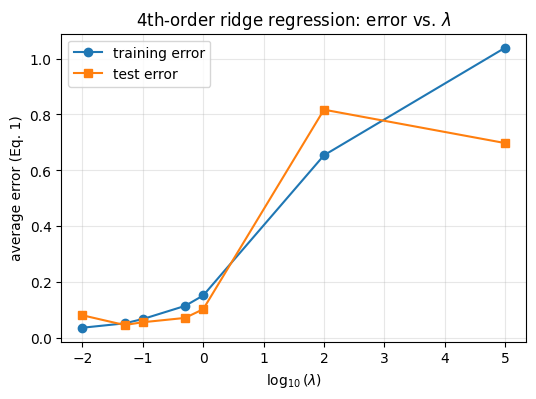

best lambda for training data: 0.01
best lambda for test data:     0.05


In [81]:
lambdas = [0.01, 0.05, 0.1, 0.5, 1, 100, 1e5]
order = 4

Xtr, Xte = design_matrix(xtr, order), design_matrix(xte, order)
ws, train_errs, test_errs = [], [], []
for lam in lambdas:
    w = fit_ridge(Xtr, ytr, lam)                 # fit on TRAINING data only
    ws.append(w)
    train_errs.append(avg_error(Xtr, ytr, w))
    test_errs.append(avg_error(Xte, yte, w))
    print(f"lambda = {lam:<8g} train = {train_errs[-1]:.4f}   test = {test_errs[-1]:.4f}")

log_lams = np.log10(lambdas)
plt.figure()
plt.plot(log_lams, train_errs, "o-", label="training error")
plt.plot(log_lams, test_errs, "s-", label="test error")
plt.xlabel(r"$\log_{10}(\lambda)$")
plt.ylabel("average error (Eq. 1)")
plt.title("4th-order ridge regression: error vs. $\\lambda$")
plt.legend()
plt.show()

print("best lambda for training data:", lambdas[int(np.argmin(train_errs))])
print("best lambda for test data:    ", lambdas[int(np.argmin(test_errs))])

**Answer:**

| $\lambda$ | Train error | Test error |
|---|---|---|
| 0.01 | **0.0374** | 0.0819 |
| 0.05 | 0.0530 | **0.0471** |
| 0.1 | 0.0684 | 0.0570 |
| 0.5 | 0.1153 | 0.0725 |
| 1 | 0.1527 | 0.1036 |
| 100 | 0.6541 | 0.8172 |
| $10^5$ | 1.0388 | 0.6978 |

- **Best for the training data: $\lambda = 0.01$.** Training error increases steadily with $\lambda$, because regularization only ever restricts the fit.
- **Best for the test data: $\lambda = 0.05$** (test error 0.0471). A little regularization reduces overfitting, so test error improves on $\lambda=0.01$ (0.0819). It also beats the unregularized 4th-order fit (0.1272) and even the cubic (0.0564).
- Beyond $\lambda\approx0.1$ the model is over-regularized and underfits, so both errors rise.

### 3(b) &nbsp; [10 points]
Plot the value of each weight parameter (including the bias $w_0$) as a function of $\lambda$.

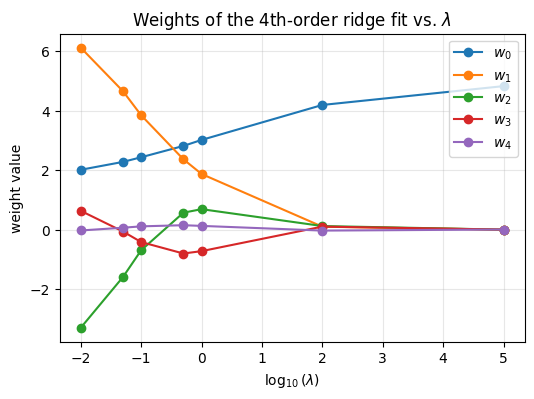

[[ 2.0156  6.1222 -3.2991  0.6332 -0.0266]
 [ 2.2804  4.6578 -1.5921 -0.0621  0.0657]
 [ 2.437   3.8491 -0.692  -0.4169  0.1117]
 [ 2.8176  2.3688  0.5714 -0.8021  0.1502]
 [ 3.0197  1.8737  0.6898 -0.7223  0.1272]
 [ 4.1963  0.1003  0.1219  0.103  -0.0307]
 [ 4.83    0.0003  0.0007  0.002   0.0056]]


In [82]:
W = np.array(ws)                                 # shape (len(lambdas), 5)

plt.figure()
for j in range(W.shape[1]):
    plt.plot(log_lams, W[:, j], "o-", label=f"$w_{j}$")
plt.xlabel(r"$\log_{10}(\lambda)$")
plt.ylabel("weight value")
plt.title("Weights of the 4th-order ridge fit vs. $\\lambda$")
plt.legend()
plt.show()

print(np.round(W, 4))

**Answer / observations:**

| $\lambda$ | $w_0$ | $w_1$ | $w_2$ | $w_3$ | $w_4$ |
|---|---|---|---|---|---|
| 0.01 | 2.0156 | 6.1222 | -3.2991 | 0.6332 | -0.0266 |
| 0.05 | 2.2804 | 4.6578 | -1.5921 | -0.0621 | 0.0657 |
| 0.1 | 2.4370 | 3.8491 | -0.6920 | -0.4169 | 0.1117 |
| 0.5 | 2.8176 | 2.3688 | 0.5714 | -0.8021 | 0.1502 |
| 1 | 3.0197 | 1.8737 | 0.6898 | -0.7223 | 0.1272 |
| 100 | 4.1963 | 0.1003 | 0.1219 | 0.1030 | -0.0307 |
| $10^5$ | 4.83 | 0.0003 | 0.0007 | 0.0020 | 0.0056 |

- As $\lambda$ grows, the penalty shrinks $w_1,\dots,w_4$ toward 0. At $\lambda=10^5$ they are essentially 0.
- The bias $w_0$ is **not** penalized, so it does not shrink to 0. It rises to about 4.83, which is the mean of the training targets, so the model becomes a constant prediction.
- Small $\lambda$ gives large weights with alternating signs (e.g. $w_1=6.12$, $w_2=-3.30$), which is the signature of an overfit polynomial.

### 3(c) &nbsp; [5 points]
Write a procedure that performs **five-fold cross-validation** on the training data (Lecture 4, p.7) and use it to pick the best $\lambda$.
Show the average validation error as a function of $\lambda$. Is the best $\lambda$ the same as in (a)?
For the best fit, plot the test data and the $\ell_2$-regularized 4th-order regression line.

In [83]:
def cross_validate(x, y, lam, order=4, k=5, seed=0):
    '''Return the mean validation error of k-fold CV for one lambda.'''
    idx = np.random.default_rng(seed).permutation(len(x))   # shuffle once, then split
    folds = np.array_split(idx, k)
    errs = []
    for f in range(k):
        val = folds[f]                                                  # held-out fold
        trn = np.concatenate([folds[g] for g in range(k) if g != f])    # other k-1 folds
        w = fit_ridge(design_matrix(x[trn], order), y[trn], lam)
        errs.append(avg_error(design_matrix(x[val], order), y[val], w))
    return np.mean(errs)

lambda = 0.01     5-fold CV error = 0.0475
lambda = 0.05     5-fold CV error = 0.0691
lambda = 0.1      5-fold CV error = 0.0876
lambda = 0.5      5-fold CV error = 0.1388
lambda = 1        5-fold CV error = 0.1852
lambda = 100      5-fold CV error = 0.6879
lambda = 100000   5-fold CV error = 1.0798
best lambda by cross-validation: 0.01


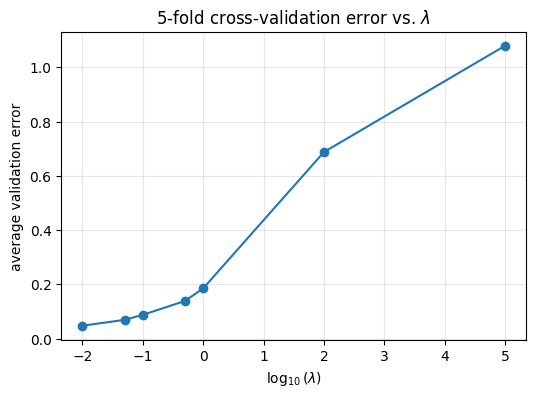

test error with best lambda: 0.08187555427386187


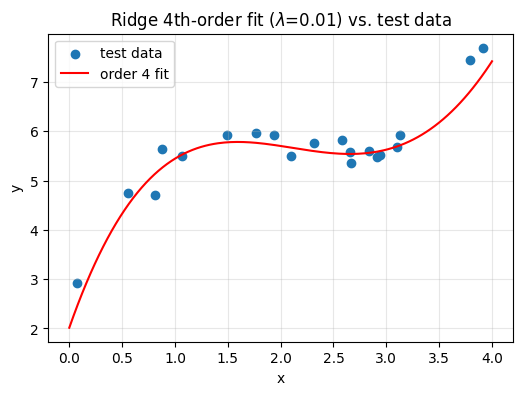

In [84]:
cv_errors = [cross_validate(xtr, ytr, lam) for lam in lambdas]
for lam, e in zip(lambdas, cv_errors):
    print(f"lambda = {lam:<8g} 5-fold CV error = {e:.4f}")

best_lam = lambdas[int(np.argmin(cv_errors))]
print("best lambda by cross-validation:", best_lam)

plt.figure()
plt.plot(log_lams, cv_errors, "o-")
plt.xlabel(r"$\log_{10}(\lambda)$")
plt.ylabel("average validation error")
plt.title("5-fold cross-validation error vs. $\\lambda$")
plt.show()

# refit on ALL training data with the chosen lambda, then evaluate on the test set
w_best = fit_ridge(design_matrix(xtr, 4), ytr, best_lam)
print("test error with best lambda:", avg_error(design_matrix(xte, 4), yte, w_best))
plot_fit(xte, yte, w_best, 4, title=f"Ridge 4th-order fit ($\\lambda$={best_lam}) vs. test data", label="test data")

**Answer:**

| $\lambda$ | 5-fold CV error |
|---|---|
| 0.01 | **0.0475** |
| 0.05 | 0.0691 |
| 0.1 | 0.0876 |
| 0.5 | 0.1388 |
| 1 | 0.1852 |
| 100 | 0.6879 |
| $10^5$ | 1.0798 |

Cross-validation selects **$\lambda = 0.01$**. This matches the best $\lambda$ for the *training* error in (a), but **not** the best $\lambda$ for the *test* error ($\lambda=0.05$). The two disagree because CV only sees 40 training points (32 per fit) and the grid is coarse, so it is a noisy estimate of generalization; the smallest $\lambda$ on the grid is also at the edge, so an even smaller value might do better. With $\lambda=0.01$ the refit on all training data has test error 0.0819.